In [44]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
import numpy as np
from sklearn.metrics import r2_score

In [36]:
veri = yf.download("USDTRY=X", period="5Y", interval="1mo")["Close"]

[*********************100%***********************]  1 of 1 completed


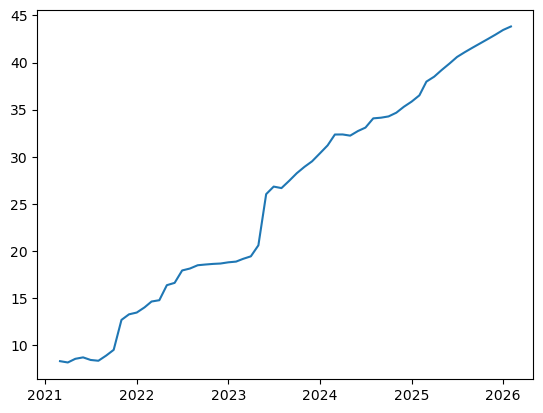

In [37]:
plt.plot(veri)

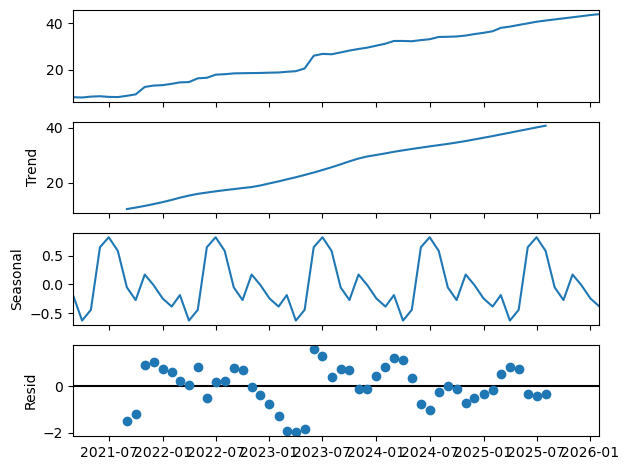

In [38]:
ho = veri.rolling(12, center=True).mean()
s = seasonal_decompose(veri)
s.plot()
t = s.trend

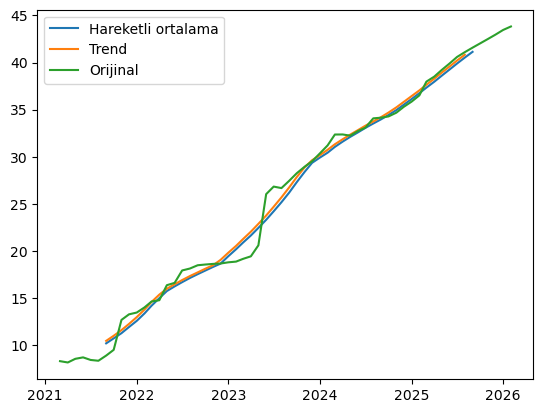

In [39]:
plt.plot(ho, label="Hareketli ortalama")
plt.plot(t, label="Trend")
plt.plot(veri, label="Orijinal")
plt.legend()

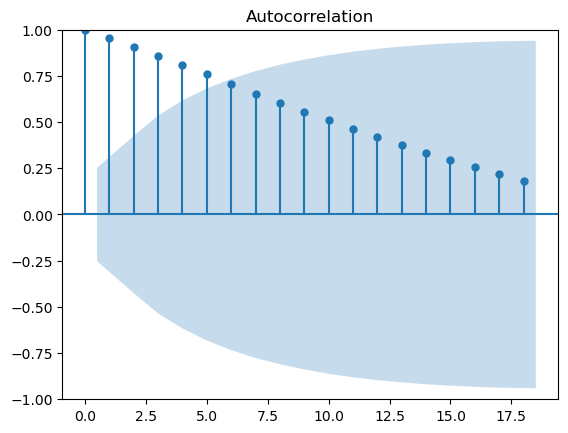

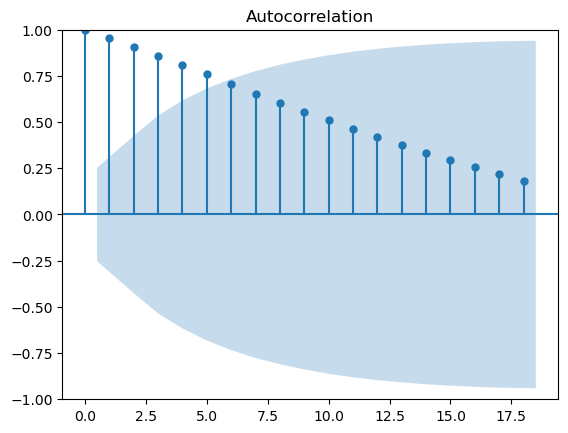

In [41]:
plot_acf(veri)

In [42]:
from arch.unitroot import ADF
ADF(veri)

Test Statistic,-0.148
P-value,0.944
Lags,0


In [52]:
veri.rename(columns={
    "USDTRY=X" : "Close"
}, inplace=True)

In [54]:
x = np.arange(len(veri))
y = veri["Close"]

In [75]:
katsayı = np.polyfit(x,y,2) # polinomun katsayılarını çıktı veriyor.
polfonk = np.poly1d(katsayı) # katsayıyı alıp tek değişkenli fonksiyon oluşturuyor.
trend = polfonk(x) # fonksiyona değerleri girerek trend serisini oluşturuyor.
r_2 = r2_score(y, trend)

Text(0.5, 1.0, 'R kare uyumu 0.99')

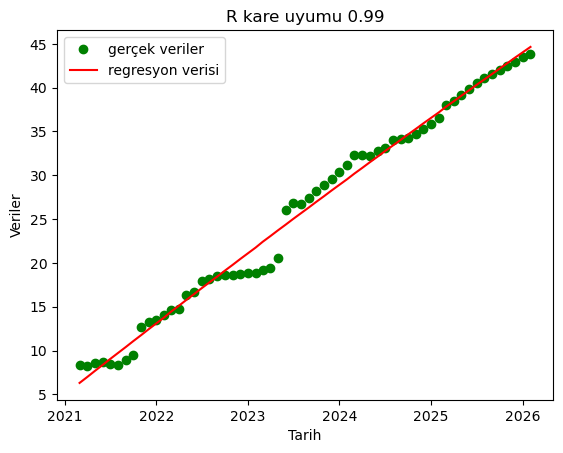

In [81]:
plt.plot(veri.index, y, "go", label="gerçek veriler")
plt.plot(veri.index, trend, "r-", label="regresyon verisi")
plt.xlabel("Tarih")
plt.ylabel("Veriler")
plt.legend()
plt.title(f"R kare uyumu {r_2:.2f}")
